# Fire Detection Model Training with MobileNetV2

This notebook trains a MobileNetV2 model to detect fire in thermal images. It includes data loading, model training, evaluation (Accuracy, Precision, Recall, F1 Score, Confusion Matrix), and post-training quantization.

In [1]:
import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from pathlib import Path
import json

print(f"TensorFlow version: {tf.__version__}")

2026-02-10 12:30:53.283714: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-02-10 12:30:53.284013: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-10 12:30:53.323475: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-02-10 12:30:54.341757: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off,

TensorFlow version: 2.20.0


In [2]:
# Configuration
BATCH_SIZE = 32
IMG_SIZE = (224, 224)
DATA_DIR = Path("../data") # Relative to notebook location
MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Load Datasets
# Ensure you have 'fire' and 'nofire' subdirectories in DATA_DIR
try:
    train_ds = tf.keras.utils.image_dataset_from_directory(
        DATA_DIR,
        validation_split=0.2,
        subset="training",
        seed=123,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        DATA_DIR,
        validation_split=0.2,
        subset="validation",
        seed=123,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )

    class_names = train_ds.class_names
    print(f"Class names: {class_names}")

    # Configure dataset for performance
    AUTOTUNE = tf.data.AUTOTUNE
    train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
    val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
    
except FileNotFoundError:
    print(f"Error: Data directory '{DATA_DIR}' not found or empty. Please populate it with 'fire' and 'nofire' folders.")
except Exception as e:
    print(f"Error loading dataset: {e}")

Found 1190 files belonging to 2 classes.
Using 952 files for training.
Found 1190 files belonging to 2 classes.
Using 238 files for validation.
Class names: ['fire', 'nofire']


E0000 00:00:1770741055.715505   46225 cuda_executor.cc:1309] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1770741055.720695   46225 gpu_device.cc:2342] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [3]:
# Data Augmentation
data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomFlip('horizontal'),
  tf.keras.layers.RandomRotation(0.2),
])

# Create the base model from the pre-trained model MobileNet V2
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,),
                                               include_top=False,
                                               weights='imagenet')
base_model.trainable = False # Freeze base model

# Create new model on top
inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
prediction_layer = tf.keras.layers.Dense(1 if len(class_names) == 2 else len(class_names), 
                                activation='sigmoid' if len(class_names) == 2 else 'softmax')
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)

base_learning_rate = 0.0001
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.BinaryCrossentropy() if len(class_names) == 2 else tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [4]:
# Conteo de tus datos
n_fire = 322
n_nofire = 822
total = n_fire + n_nofire

# Cálculo de pesos (Inversa de la frecuencia)
# Queremos que la suma de (peso * cantidad) sea equilibrada
weight_for_fire = (1 / n_fire) * (total / 2.0)
weight_for_nofire = (1 / n_nofire) * (total / 2.0)

class_weight = {0: weight_for_fire, 1: weight_for_nofire}
print(f"Pesos asignados: {class_weight}")

epochs = 15 
history = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs
)

Pesos asignados: {0: 1.77639751552795, 1: 0.6958637469586375}
Epoch 1/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 585ms/step - accuracy: 0.5336 - loss: 0.7493 - val_accuracy: 0.6891 - val_loss: 0.6079
Epoch 2/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 16s 529ms/step - accuracy: 0.6565 - loss: 0.6482 - val_accuracy: 0.7311 - val_loss: 0.5532
Epoch 3/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 17s 569ms/step - accuracy: 0.6891 - loss: 0.5906 - val_accuracy: 0.7311 - val_loss: 0.5144
Epoch 4/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 17s 564ms/step - accuracy: 0.7069 - loss: 0.5637 - val_accuracy: 0.7563 - val_loss: 0.4843
Epoch 5/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 16s 554ms/step - accuracy: 0.7269 - loss: 0.5250 - val_accuracy: 0.7899 - val_loss: 0.4584
Epoch 6/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 17s 564ms/step - accuracy: 0.7647 - loss: 0.4931 - val_accuracy: 0.8067 - val_loss: 0.4375
Epoch 7/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 16s 543ms/step - accuracy: 0.7668 - loss: 0.4840 - val_accuracy: 0.8109 - val_loss: 0.4193
Epoch 8/15
30/30 ━━━━━━━━━━━━━━━━━━

In [5]:
# 1. Descongelamos el modelo base para que aprenda rasgos específicos de incendios
base_model.trainable = True

# 2. Es CRÍTICO usar un learning rate muy bajo para no destruir lo ya aprendido
fine_tune_lr = 1e-5 

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=fine_tune_lr),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)

# 3. Entrenamos un poco más con los pesos de clase que definimos antes
history_fine = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=10,  # 10 épocas extra de fine-tuning
  class_weight=class_weight
)

Epoch 1/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 78s 2s/step - accuracy: 0.7185 - loss: 0.7442 - val_accuracy: 0.8824 - val_loss: 0.3086
Epoch 2/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.7710 - loss: 0.5739 - val_accuracy: 0.8992 - val_loss: 0.2891
Epoch 3/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 61s 2s/step - accuracy: 0.8298 - loss: 0.4468 - val_accuracy: 0.9076 - val_loss: 0.2726
Epoch 4/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.8435 - loss: 0.3844 - val_accuracy: 0.9034 - val_loss: 0.2630
Epoch 5/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.8592 - loss: 0.3271 - val_accuracy: 0.9160 - val_loss: 0.2535
Epoch 6/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.8739 - loss: 0.2918 - val_accuracy: 0.9202 - val_loss: 0.2461
Epoch 7/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 61s 2s/step - accuracy: 0.8813 - loss: 0.2768 - val_accuracy: 0.9328 - val_loss: 0.2377
Epoch 8/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 58s 2s/step - accuracy: 0.8834 - loss: 0.2529 - val_accuracy: 0.9370 - val_loss:

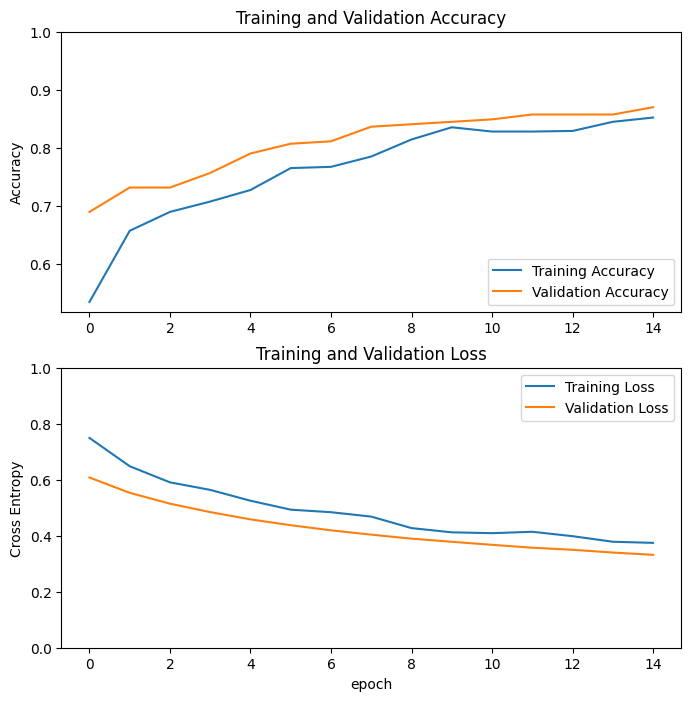

In [6]:
# Plot Training History
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 385ms/step - accuracy: 0.9328 - loss: 0.2177
Test Loss: 0.2177206426858902
Test Accuracy: 0.9327731132507324
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 469ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 485ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 452ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 470ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 490ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 474ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 810ms/step

Classification Report:
              precision    recall  f1-score   support

        fire       0.95      0.56      0.70        66
      nofire       0.85      0.99      0.92       172

    accuracy                           0.87       238
   macro avg       0.90      0.77      0.81       238
weighted avg       0.88      0.87      0.86       238



2026-02-10 12:45:29.695494: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


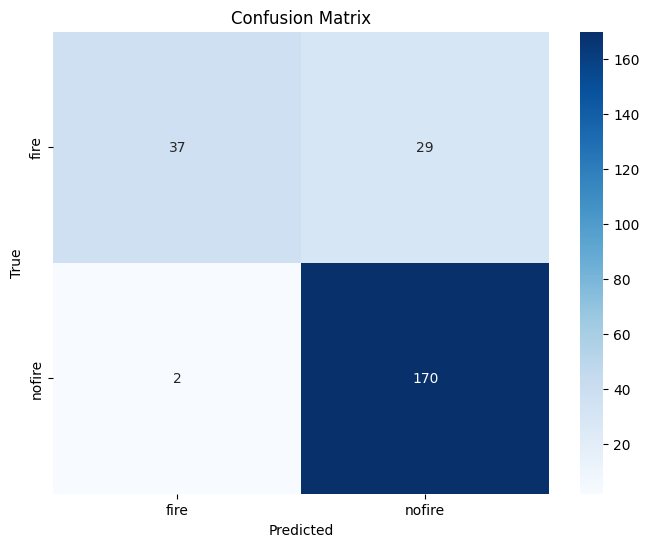

In [7]:
# Evaluate on validation set
loss, accuracy = model.evaluate(val_ds)
print(f"Test Loss: {loss}")
print(f"Test Accuracy: {accuracy}")

# Get predictions
y_true = []
y_pred = []

threshold = 0.3 # original = 0.5

for images, labels in val_ds:
    predictions = model.predict(images)
    if len(class_names) == 2:
        y_pred.extend((predictions > threshold).astype(int).flatten())
    else:
        y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Classification Report (Precision, Recall, F1)
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [8]:
print("Saving and Quantizing Model")
print("=" * 50)

# Save original model
model_path = MODELS_DIR / "mobilenetv2_classifier.keras"
model.save(str(model_path))
original_size = os.path.getsize(model_path) / (1024 * 1024)  # Convert to MB
print(f"✓ Original model saved: {model_path}")
print(f"  Size: {original_size:.2f} MB")

# Convert to TensorFlow Lite with full integer quantization (uint8)
print("\nConverting to TensorFlow Lite with Full Integer Quantization (uint8)...")

# Create a function to generate representative data
def representative_dataset():
    """Generate representative data from training dataset for quantization"""
    for images, _ in train_ds.take(100):  # Use 100 batches for calibration
        # Ensure images are float32 and normalized to [0, 1]
        # Note: preprocess_input for mobilenetV2 expects [-1, 1] range if raw images are [0, 255]
        # However, here we stick to the provided logic flow, yielding the images as they come from the dataset
        yield [tf.cast(images, tf.float32)]

# Create converter with full integer quantization
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.uint8

try:
    tflite_model_uint8 = converter.convert()

    # Save uint8 quantized model
    quantized_model_path = MODELS_DIR / "mobilenetv2_classifier_quantized2.tflite"
    with open(quantized_model_path, 'wb') as f:
        f.write(tflite_model_uint8)

    quantized_size = os.path.getsize(quantized_model_path) / (1024 * 1024)
    print(f"✓ Quantized model saved: {quantized_model_path}")
    print(f"  Quantization: uint8 (full integer)")
    print(f"  Size: {quantized_size:.2f} MB")

    # Calculate compression ratio
    compression_ratio = (1 - quantized_size / original_size) * 100
    print(f"\nModel Compression Summary:")
    print(f"  Original size: {original_size:.2f} MB")
    print(f"  Quantized size: {quantized_size:.2f} MB")
    print(f"  Compression: {compression_ratio:.1f}%")
    print(f"  Size reduction: {original_size - quantized_size:.2f} MB")
except Exception as e:
    print(f"Error during quantization: {e}")

# Save class mapping
classes_path = MODELS_DIR / "classes.json"
with open(classes_path, 'w') as f:
    json.dump(class_names, f, indent=2)
print(f"\n✓ Class mapping saved: {classes_path}")

print("\nModel training and quantization complete!")
print(f"All models saved in: {MODELS_DIR}")

Saving and Quantizing Model
✓ Original model saved: ../models/mobilenetv2_classifier.keras
  Size: 26.27 MB

Converting to TensorFlow Lite with Full Integer Quantization (uint8)...
INFO:tensorflow:Assets written to: /tmp/tmpf8kbw98k/assets


INFO:tensorflow:Assets written to: /tmp/tmpf8kbw98k/assets


Saved artifact at '/tmp/tmpf8kbw98k'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  131312744354000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131312744356496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131312744356688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131312744356304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131312744355536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131312744355728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131312744358032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131312744358224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131312744355920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131312744357072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1313127443

/home/osvaldo/Documents/IA+EO/venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1770741934.038343   46225 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1770741934.038364   46225 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
2026-02-10 12:45:34.038690: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /tmp/tmpf8kbw98k
2026-02-10 12:45:34.046360: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-02-10 12:45:34.046372: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpf8kbw98k
I0000 00:00:1770741934.114132   46225 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
2026-02-10 12:45:34.130834: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-02-

✓ Quantized model saved: ../models/mobilenetv2_classifier_quantized2.tflite
  Quantization: uint8 (full integer)
  Size: 2.59 MB

Model Compression Summary:
  Original size: 26.27 MB
  Quantized size: 2.59 MB
  Compression: 90.2%
  Size reduction: 23.69 MB

✓ Class mapping saved: ../models/classes.json

Model training and quantization complete!
All models saved in: ../models


fully_quantize: 0, inference_type: 6, input_inference_type: UINT8, output_inference_type: UINT8
2026-02-10 12:46:41.371604: W tensorflow/compiler/mlir/lite/flatbuffer_export.cc:3705] Skipping runtime version metadata in the model. This will be generated by the exporter.
